In [1]:
import json
import pandas as pd

with open('../Datasets/dataset.json', 'r') as file:
    data = json.load(file)
    df = pd.DataFrame(data)

In [2]:
pip install matplotlib


[notice] A new release of pip is available: 23.0.1 -> 26.2.1
[notice] To update, run: pip install --upgrade pip
Note: you may need to restart the kernel to use updated packages.


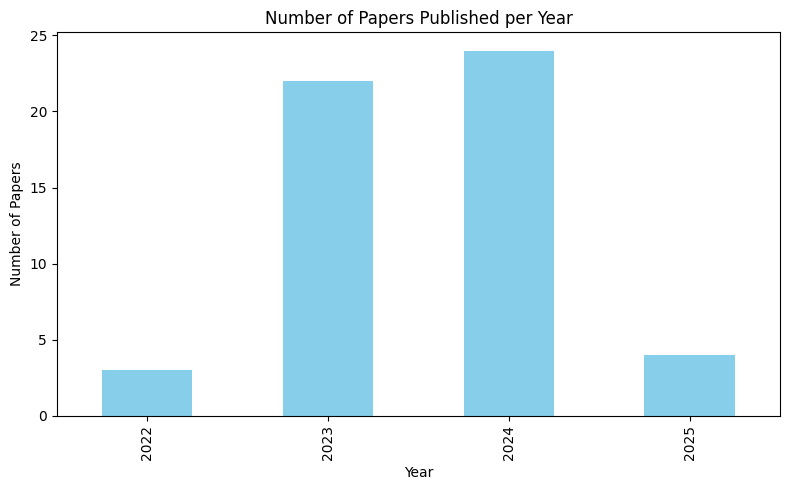

In [3]:
import matplotlib.pyplot as plt

papers_per_year = df['year'].value_counts().sort_index()
plt.figure(figsize=(8, 5))
papers_per_year.plot(kind='bar', color='skyblue')
plt.xlabel('Year')
plt.ylabel('Number of Papers')
plt.title('Number of Papers Published per Year')
plt.tight_layout()
plt.show()

<Figure size 800x500 with 0 Axes>

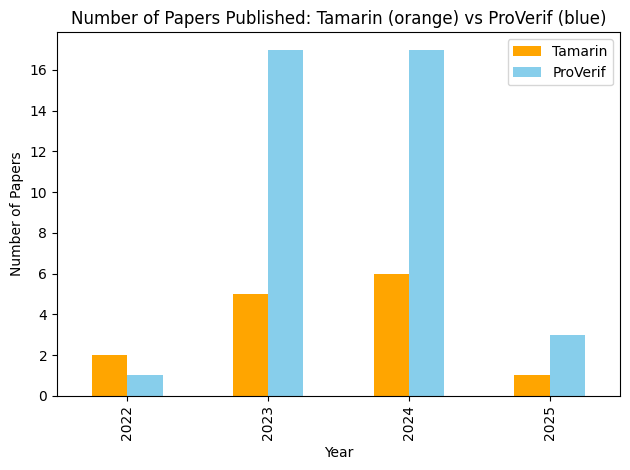

In [4]:
from matplotlib.ticker import MaxNLocator

papers_by_year_tool = df.groupby(['year', 'tool']).size().unstack(fill_value=0)

plt.figure(figsize=(8, 5))
ax = papers_by_year_tool[['Tamarin', 'ProVerif']].plot(
    kind='bar',
    color=['orange', 'skyblue']
)
ax.yaxis.set_major_locator(MaxNLocator(integer=True))
plt.xlabel('Year')
plt.ylabel('Number of Papers')
plt.title('Number of Papers Published: Tamarin (orange) vs ProVerif (blue)')
plt.legend(['Tamarin', 'ProVerif'])
plt.tight_layout()
plt.show()


In [5]:
unique_properties = set()
for props in df['properties']:
    for prop in props.split(','):
        unique_properties.add(prop.strip())

print(sorted(unique_properties))
for prop in sorted(unique_properties):
    print(f"- {prop}")

['aliveness', 'anonymity', 'attestation', 'authentication', 'confidentiality', 'correctness', 'eligibility', 'equivalence properties', 'fairness', 'forward secrecy', 'injective agreement', 'integrity', 'key escrow freeness', 'mutual authentication', 'no-double-spending', 'non-equivocation', 'non-frameability', 'non-injective agreement', 'non-repudiation', 'off-line verifiable', 'one-time group agreement', 'post-compromise security', 'privacy', 'profile binding', 'reachability', 'receipt-freeness', 'remote attestation', 'secrecy', 'secure key agreement', 'secure key exchange', 'session key agreement', 'single-blindness', 'traceability', 'transferable authentication', 'unforgeability', 'unlinkability', 'untraceability', 'verifiability', 'verification of intent', 'weak agreement']
- aliveness
- anonymity
- attestation
- authentication
- confidentiality
- correctness
- eligibility
- equivalence properties
- fairness
- forward secrecy
- injective agreement
- integrity
- key escrow freeness


In [6]:
from collections import Counter

# Flatten all properties into a list
all_properties = []
for props in df['properties']:
    for prop in props.split(','):
        all_properties.append(prop.strip())

property_counts = Counter(all_properties)

# Display as a sorted DataFrame
property_counts_df = pd.DataFrame.from_dict(property_counts, orient='index', columns=['count']).sort_values('count', ascending=False)
print(property_counts_df)

                             count
integrity                       21
forward secrecy                 17
anonymity                       16
confidentiality                 16
authentication                  14
secrecy                         12
mutual authentication           12
untraceability                   8
privacy                          8
unlinkability                    7
injective agreement              5
non-injective agreement          4
traceability                     4
correctness                      3
non-repudiation                  3
session key agreement            2
secure key exchange              2
weak agreement                   2
verifiability                    2
post-compromise security         2
verification of intent           1
single-blindness                 1
profile binding                  1
transferable authentication      1
remote attestation               1
non-equivocation                 1
unforgeability                   1
reachability        

<Figure size 1000x600 with 0 Axes>

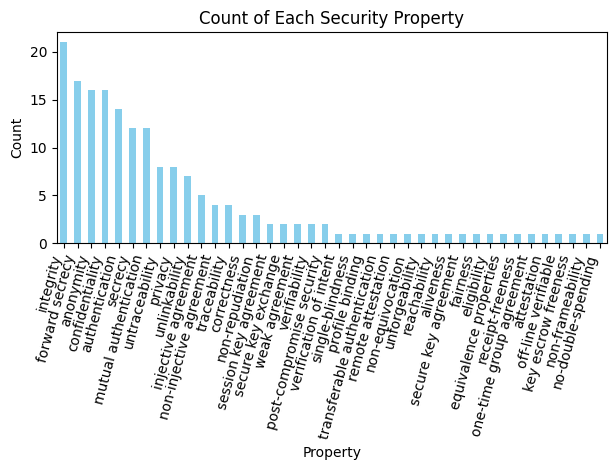

In [7]:
plt.figure(figsize=(10, 6))
property_counts_df.plot(kind='bar', legend=False, color='skyblue')
plt.xlabel('Property')
plt.ylabel('Count')
plt.title('Count of Each Security Property')
plt.xticks(rotation=75, ha='right')
plt.tight_layout()
plt.show()

In [8]:
#
import IPython.display as display

single_occurrence_properties = [prop for prop, count in property_counts.items() if count == 1]
html = "<div style='max-height:200px; overflow:auto; border:1px solid #ccc; padding:10px;'>"
html += "<ul style='margin:0; padding-left:20px;'>"
for prop in single_occurrence_properties:
    html += f"<li>{prop}</li>"
html += "</ul></div>"

display.display(display.HTML(html))

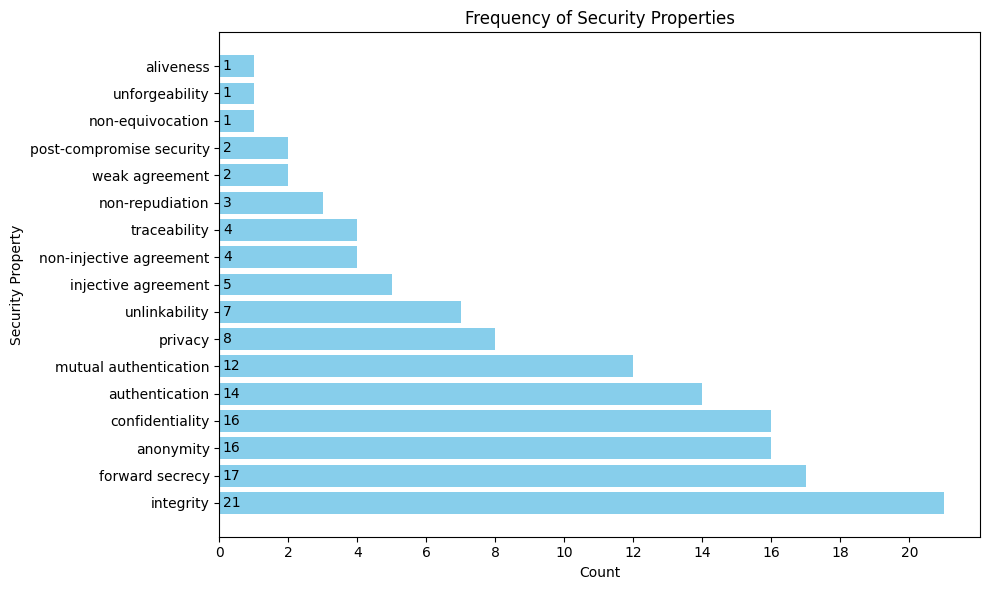

In [9]:
import numpy as np
import matplotlib.pyplot as plt

included_list = ["authentication", "confidentiality", "integrity", "aliveness", "weak agreement", "non-injective agreement", "injective agreement", "mutual authentication", "integrity", "unforgeability", "non-equivocation", "confidentiality", "forward secrecy", "backward secrecy", "post-compromise security", "privacy", "anonymity", "unlinkability", "accountability", "traceability", "non-repudiation"]


# normalize case and fix typo in index
property_counts_df.index = property_counts_df.index.str.lower().str.strip()
included_list = [p.lower() for p in included_list]

# filter
filtered_df = property_counts_df[property_counts_df.index.isin(included_list)]

# plot horizontal bars
fig, ax = plt.subplots(figsize=(10, 6))
bars = ax.barh(filtered_df.index, filtered_df.values.flatten(), color='skyblue')

# labels
ax.set_xlabel('Count')
ax.set_ylabel('Security Property')
ax.set_title('Frequency of Security Properties')

# set x-axis to only integer ticks
max_val = int(filtered_df.values.max())
ax.set_xticks(np.arange(0, max_val + 1, 2))

# add integer labels on the left of each bar
for bar, value in zip(bars, filtered_df.values.flatten()):
    if float(value).is_integer():  # show only integers
        ax.text(
            0.1,                      # small offset from y-axis
            bar.get_y() + bar.get_height() / 2,
            str(int(value)),
            va='center',
            ha='left',
            color='black'
        )

plt.tight_layout()
plt.show()


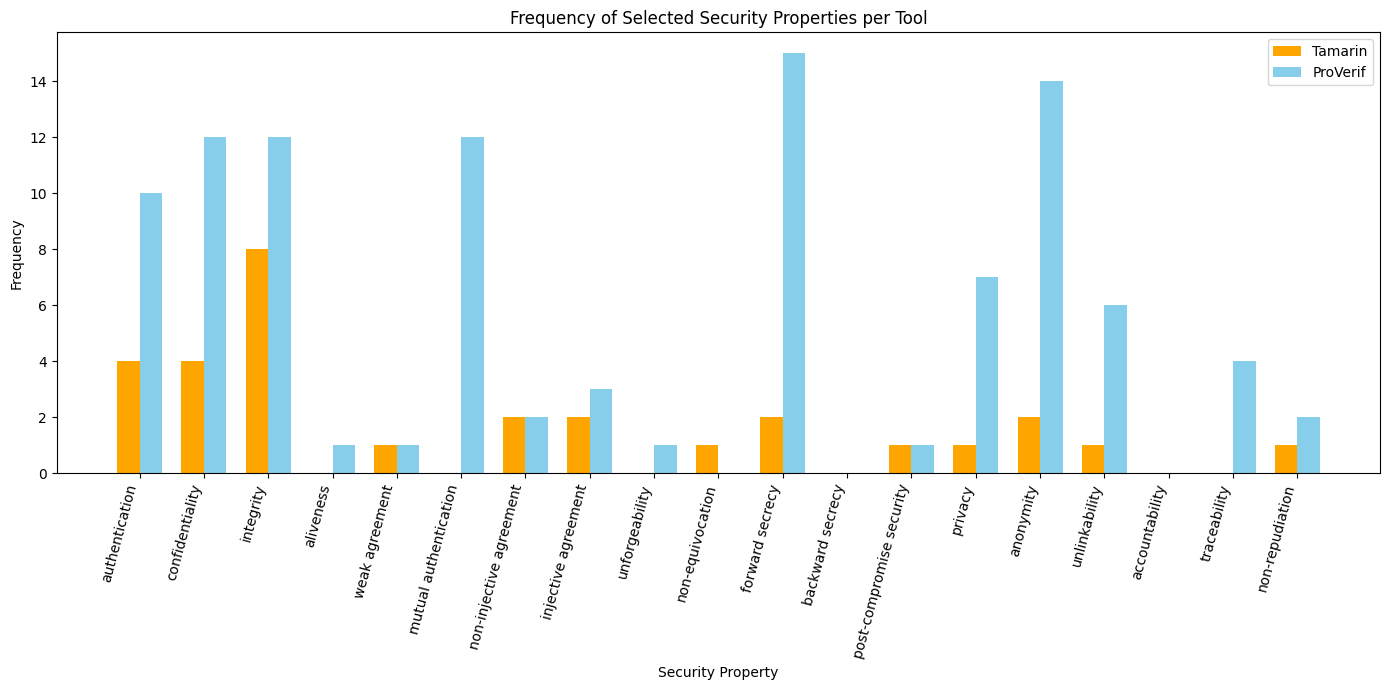

In [10]:
import matplotlib.pyplot as plt
import numpy as np

included_list = [
    "authentication", "confidentiality", "integrity", "aliveness", "weak agreement",
    "mutual authentication", "non-injective agreement", "injective agreement", "unforgeability", "non-equivocation",
    "forward secrecy", "backward secrecy", "post-compromise security", "privacy", "anonymity",
    "unlinkability", "accountability", "traceability", "non-repudiation"
]
included_list = [p.lower() for p in included_list]

# Prepare a DataFrame with one row per property per tool
rows = []
for _, row in df.iterrows():
    tool = row['tool']
    for prop in row['properties'].split(','):
        prop_clean = prop.strip().lower()
        if prop_clean in included_list:
            rows.append({'tool': tool, 'property': prop_clean})

prop_tool_df = pd.DataFrame(rows)

# Count frequency of each property per tool
freq = prop_tool_df.groupby(['property', 'tool']).size().unstack(fill_value=0)
freq = freq.reindex(included_list)  # ensure order

# Plot: grouped bar chart (one group per property, two bars per group)
fig, ax = plt.subplots(figsize=(14, 7))
bar_width = 0.35
index = np.arange(len(included_list))

tamarin_counts = freq.get('Tamarin', pd.Series([0]*len(included_list), index=included_list))
proverif_counts = freq.get('ProVerif', pd.Series([0]*len(included_list), index=included_list))

bars1 = ax.bar(index - bar_width/2, tamarin_counts, bar_width, label='Tamarin', color='orange')
bars2 = ax.bar(index + bar_width/2, proverif_counts, bar_width, label='ProVerif', color='skyblue')

ax.set_xlabel('Security Property')
ax.set_ylabel('Frequency')
ax.set_title('Frequency of Selected Security Properties per Tool')
ax.set_xticks(index)
ax.set_xticklabels(included_list, rotation=75, ha='right')
ax.legend()
plt.tight_layout()
plt.show()

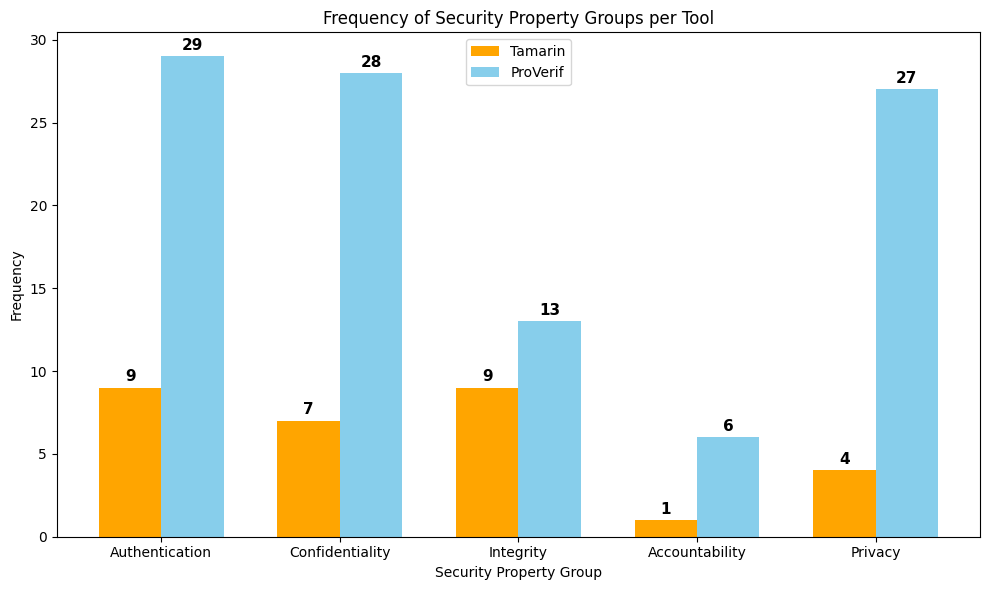

In [18]:
import matplotlib.pyplot as plt
import numpy as np

# Define property groups
authentication_list = ["authentication", "mutual authentication", "aliveness", "weak agreement", "non-injective agreement", "injective agreement"]
confidentiality_list = ["confidentiality", "forward secrecy", "backward secrecy", "post-compromise security"]
integrity_list = ["integrity", "unforgeability", "non-equivocation"]
accountability_list = ["accountability", "traceability", "non-repudiation"]
privacy_list = ["privacy", "anonymity", "unlinkability"]

group_dict = {
    "Authentication": authentication_list,
    "Confidentiality": confidentiality_list,
    "Integrity": integrity_list,
    "Accountability": accountability_list,
    "Privacy": privacy_list
}

# Prepare a DataFrame with one row per property per tool
rows = []
for _, row in df.iterrows():
    tool = row['tool']
    for prop in row['properties'].split(','):
        prop_clean = prop.strip().lower()
        for group, props in group_dict.items():
            if prop_clean in props:
                rows.append({'tool': tool, 'group': group})

import pandas as pd
prop_tool_df = pd.DataFrame(rows)

# Count frequency of each group per tool
freq = prop_tool_df.groupby(['group', 'tool']).size().unstack(fill_value=0)
freq = freq.reindex(group_dict.keys())  # ensure order

# Plot: grouped bar chart (one group per property group, two bars per group)
fig, ax = plt.subplots(figsize=(10, 6))
bar_width = 0.35
index = np.arange(len(group_dict))

tamarin_counts = freq.get('Tamarin', pd.Series([0]*len(group_dict), index=group_dict.keys()))
proverif_counts = freq.get('ProVerif', pd.Series([0]*len(group_dict), index=group_dict.keys()))

bars1 = ax.bar(index - bar_width/2, tamarin_counts, bar_width, label='Tamarin', color='orange')
bars2 = ax.bar(index + bar_width/2, proverif_counts, bar_width, label='ProVerif', color='skyblue')

# Show the number for each bar on the chart
for bar in bars1:
    height = bar.get_height()
    ax.text(
        bar.get_x() + bar.get_width()/2, height + 0.2, str(int(height)),
        ha='center', va='bottom', fontsize=11, color='black', fontweight='bold'
    )
for bar in bars2:
    height = bar.get_height()
    ax.text(
        bar.get_x() + bar.get_width()/2, height + 0.2, str(int(height)),
        ha='center', va='bottom', fontsize=11, color='black', fontweight='bold'
    )

ax.set_xlabel('Security Property Group')
ax.set_ylabel('Frequency')
ax.set_title('Frequency of Security Property Groups per Tool')
ax.set_xticks(index)
ax.set_xticklabels(list(group_dict.keys()))
ax.legend()
plt.tight_layout()
plt.show()

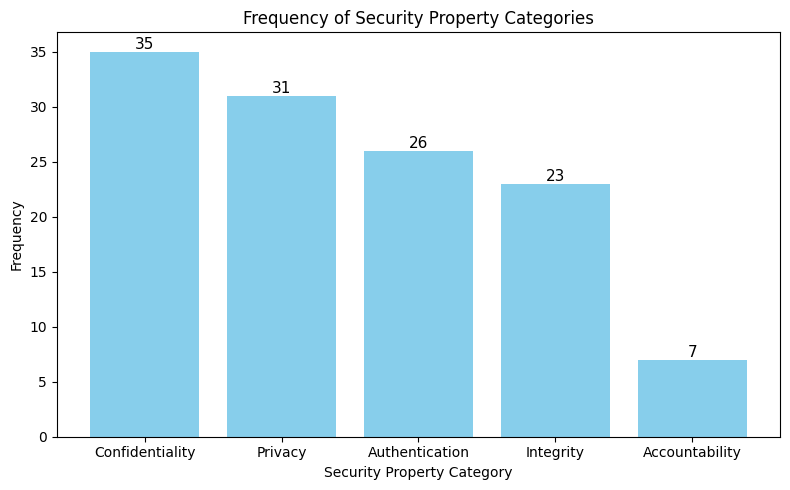

In [12]:
import matplotlib.pyplot as plt
import numpy as np

# Define property groups
authentication_list = ["authentication", "aliveness", "weak agreement", "non-injective agreement", "injective agreement"]
confidentiality_list = ["confidentiality", "forward secrecy", "backward secrecy", "post-compromise security"]
integrity_list = ["integrity", "unforgeability", "non-equivocation"]
accountability_list = ["accountability", "traceability", "non-repudiation"]
privacy_list = ["privacy", "anonymity", "unlinkability"]

group_dict = {
    "Authentication": authentication_list,
    "Confidentiality": confidentiality_list,
    "Integrity": integrity_list,
    "Accountability": accountability_list,
    "Privacy": privacy_list
}

# Prepare a DataFrame with one row per property
all_props = []
for props in df['properties']:
    for prop in props.split(','):
        prop_clean = prop.strip().lower()
        for group, props_list in group_dict.items():
            if prop_clean in props_list:
                all_props.append(group)

import pandas as pd
group_counts = pd.Series(all_props).value_counts().reindex(group_dict.keys(), fill_value=0)

# Sort by frequency descending
group_counts = group_counts.sort_values(ascending=False)

# Plot bar chart (not grouped by tool)
plt.figure(figsize=(8, 5))
bars = plt.bar(group_counts.index, group_counts.values, color='skyblue')
plt.xlabel('Security Property Category')
plt.ylabel('Frequency')
plt.title('Frequency of Security Property Categories')

# Add value labels on top of each bar
for bar in bars:
    height = bar.get_height()
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        height,
        str(int(height)),
        ha='center',
        va='bottom',
        fontsize=11
    )

plt.tight_layout()
plt.show()

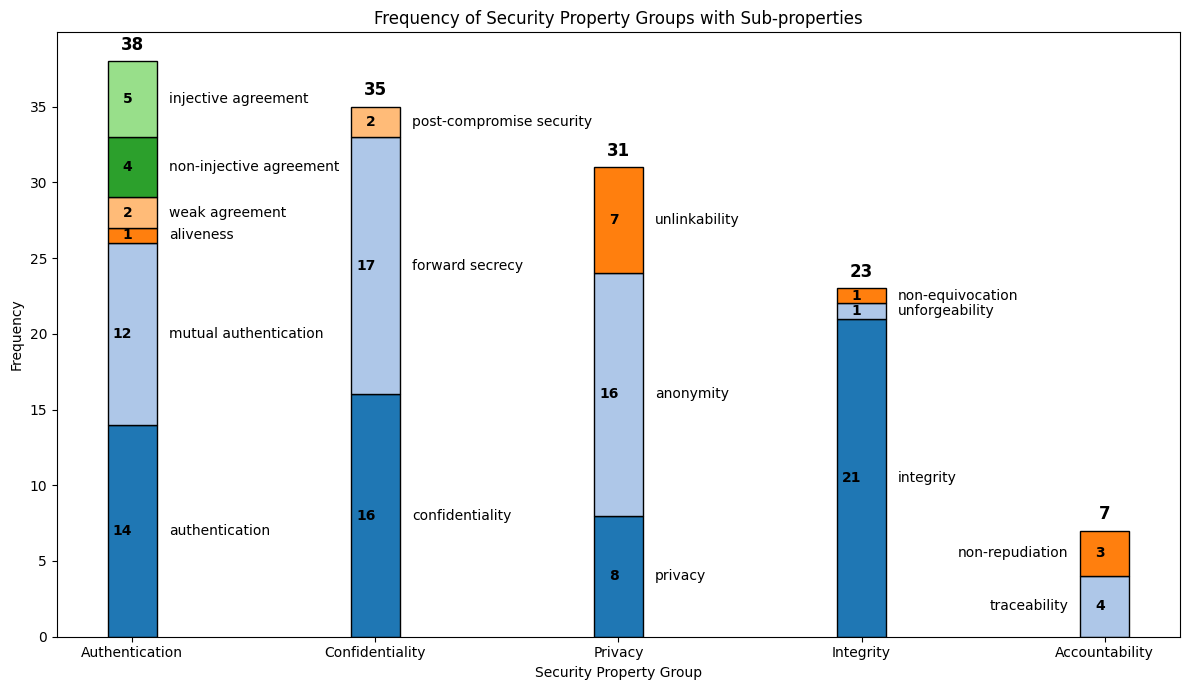

In [16]:
import matplotlib.pyplot as plt
import numpy as np

# Define property groups
authentication_list = ["authentication", "mutual authentication", "aliveness", "weak agreement", "non-injective agreement", "injective agreement"]
confidentiality_list = ["confidentiality", "forward secrecy", "backward secrecy", "post-compromise security"]
integrity_list = ["integrity", "unforgeability", "non-equivocation"]
accountability_list = ["accountability", "traceability", "non-repudiation"]
privacy_list = ["privacy", "anonymity", "unlinkability"]

group_dict = {
    "Authentication": authentication_list,
    "Confidentiality": confidentiality_list,
    "Integrity": integrity_list,
    "Accountability": accountability_list,
    "Privacy": privacy_list
}

from collections import Counter, OrderedDict

# Count sub-properties for each group
sub_counts = {group: Counter() for group in group_dict}
for props in df['properties']:
    for prop in props.split(','):
        prop_clean = prop.strip().lower()
        for group, props_list in group_dict.items():
            if prop_clean in props_list:
                sub_counts[group][prop_clean] += 1

# Prepare group counts (sum of sub-properties)
group_counts = OrderedDict()
for group in group_dict:
    group_counts[group] = sum(sub_counts[group].values())

# Sort by frequency descending
group_counts = OrderedDict(sorted(group_counts.items(), key=lambda x: x[1], reverse=True))

# Plot stacked bar chart
fig, ax = plt.subplots(figsize=(12, 7))
bar_positions = np.arange(len(group_counts))
bottom = np.zeros(len(group_counts))

colors = plt.cm.tab20.colors  # More distinct colors for better visibility

for i, group in enumerate(group_counts):
    for j, sub_prop in enumerate(group_dict[group]):
        count = sub_counts[group][sub_prop]
        if count > 0:
            color = colors[j % len(colors)]
            bar = ax.bar(i, count, bottom=bottom[i], color=color, edgecolor='black', width=0.2)
            # Place number on the bar, label to the right of the number
            y = bottom[i] + count / 2
            ax.text(
                i, y, f"{count}", ha='right', va='center', fontsize=10, color='black', fontweight='bold', clip_on=True
            )
            if i > 3:
                ax.text(
                    i - 0.15 , y, f"{sub_prop}", ha='right', va='center', fontsize=10, color='black', clip_on=True
                )
            else:
                ax.text(
                    i + 0.15, y, f"{sub_prop}", ha='left', va='center', fontsize=10, color='black', clip_on=True
                )
            bottom[i] += count

# Add total value on top of each bar
for i, (group, total) in enumerate(group_counts.items()):
    ax.text(i, total + 0.5, str(int(total)), ha='center', va='bottom', fontsize=12, fontweight='bold')

ax.set_xticks(bar_positions)
ax.set_xticklabels(list(group_counts.keys()))
ax.set_xlabel('Security Property Group')
ax.set_ylabel('Frequency')
ax.set_title('Frequency of Security Property Groups with Sub-properties')
plt.tight_layout()
plt.show()

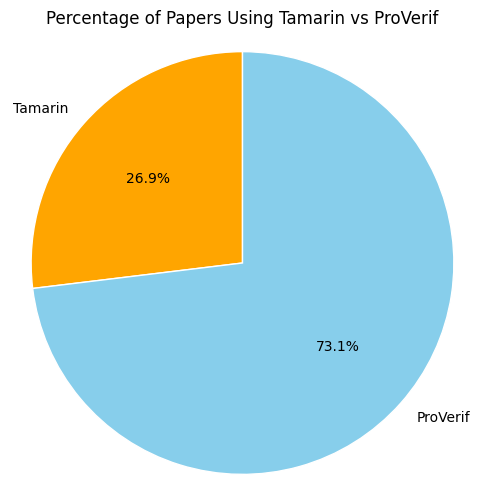

In [14]:
import matplotlib.pyplot as plt

# Count papers per tool
tool_counts = df['tool'].value_counts().reindex(['Tamarin', 'ProVerif'], fill_value=0)

# Pie chart
plt.figure(figsize=(6, 6))
plt.pie(
    tool_counts,
    labels=tool_counts.index,
    autopct='%1.1f%%',
    startangle=90,
    colors=['orange', 'skyblue'],
    wedgeprops={'edgecolor': 'white'}
)
plt.title('Percentage of Papers Using Tamarin vs ProVerif')
plt.axis('equal')
plt.show()

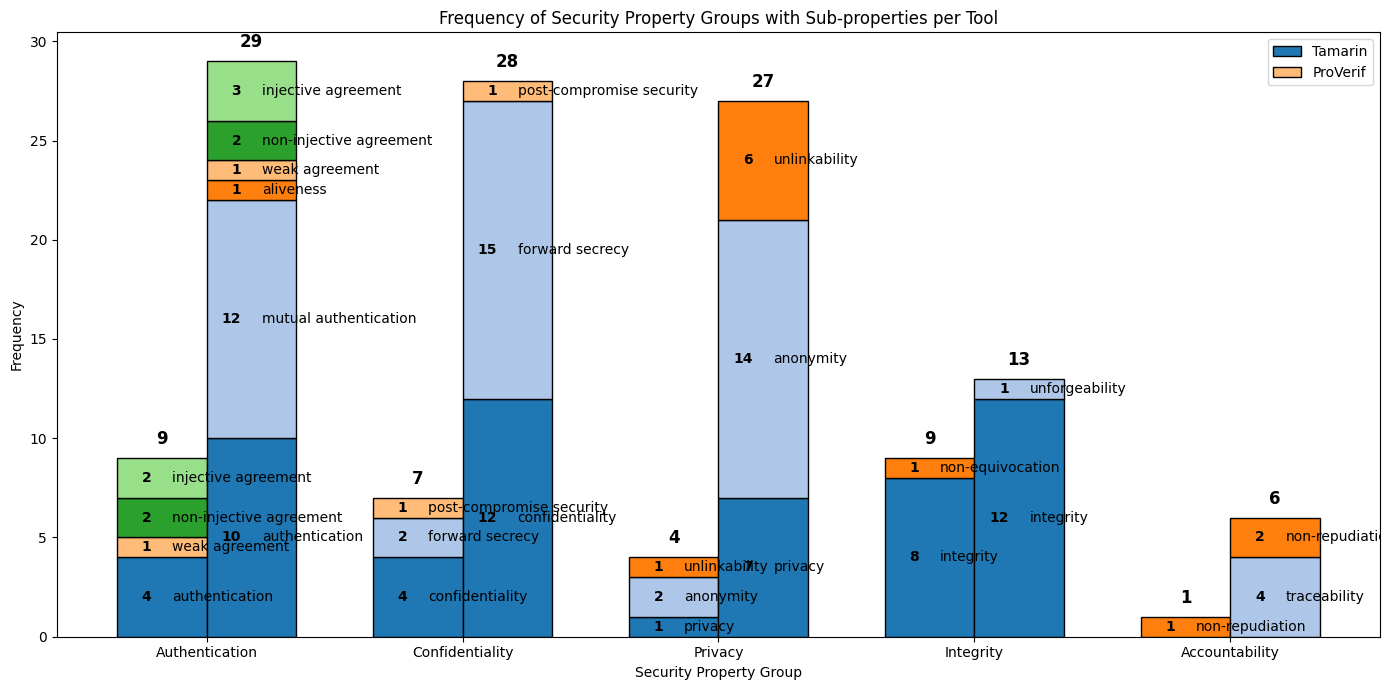

In [17]:
import matplotlib.pyplot as plt
import numpy as np

# Define property groups
authentication_list = ["authentication", "mutual authentication", "aliveness", "weak agreement", "non-injective agreement", "injective agreement"]
confidentiality_list = ["confidentiality", "forward secrecy", "backward secrecy", "post-compromise security"]
integrity_list = ["integrity", "unforgeability", "non-equivocation"]
accountability_list = ["accountability", "traceability", "non-repudiation"]
privacy_list = ["privacy", "anonymity", "unlinkability"]

group_dict = {
    "Authentication": authentication_list,
    "Confidentiality": confidentiality_list,
    "Integrity": integrity_list,
    "Accountability": accountability_list,
    "Privacy": privacy_list
}

from collections import Counter, OrderedDict

tools = ['Tamarin', 'ProVerif']
colors = plt.cm.tab20.colors  # More distinct colors for better visibility

# Prepare sub-property counts per group per tool
sub_counts_tool = {tool: {group: Counter() for group in group_dict} for tool in tools}
for _, row in df.iterrows():
    tool = row['tool']
    if tool not in tools:
        continue
    for prop in row['properties'].split(','):
        prop_clean = prop.strip().lower()
        for group, props_list in group_dict.items():
            if prop_clean in props_list:
                sub_counts_tool[tool][group][prop_clean] += 1

# Prepare group counts (sum of sub-properties) per tool
group_counts_tool = {tool: OrderedDict() for tool in tools}
for tool in tools:
    for group in group_dict:
        group_counts_tool[tool][group] = sum(sub_counts_tool[tool][group].values())

# Sort groups by total frequency (sum over both tools)
group_order = sorted(
    group_dict.keys(),
    key=lambda g: group_counts_tool['Tamarin'][g] + group_counts_tool['ProVerif'][g],
    reverse=True
)

# Plot
fig, ax = plt.subplots(figsize=(14, 7))
bar_width = 0.35
index = np.arange(len(group_order))

for t, tool in enumerate(tools):
    bottom = np.zeros(len(group_order))
    for j, group in enumerate(group_order):
        for k, sub_prop in enumerate(group_dict[group]):
            count = sub_counts_tool[tool][group][sub_prop]
            if count > 0:
                color = colors[k % len(colors)]
                bar = ax.bar(
                    index[j] + (t - 0.5) * bar_width,
                    count,
                    bar_width,
                    bottom=bottom[j],
                    color=color,
                    edgecolor='black'
                )
                y = bottom[j] + count / 2
                # Number on the bar, label to the right of the number
                ax.text(
                    index[j] + (t - 0.5) * bar_width - 0.04,
                    y,
                    f"{count}",
                    ha='right',
                    va='center',
                    fontsize=10,
                    color='black',
                    fontweight='bold',
                    clip_on=True
                )
                ax.text(
                    index[j] + (t - 0.5) * bar_width + 0.04,
                    y,
                    f"{sub_prop}",
                    ha='left',
                    va='center',
                    fontsize=10,
                    color='black',
                    clip_on=True
                )
                bottom[j] += count
    # Add total value on top of each bar
    for j, group in enumerate(group_order):
        total = group_counts_tool[tool][group]
        if total > 0:
            ax.text(
                index[j] + (t - 0.5) * bar_width,
                total + 0.5,
                str(int(total)),
                ha='center',
                va='bottom',
                fontsize=12,
                fontweight='bold'
            )

ax.set_xticks(index)
ax.set_xticklabels(group_order)
ax.set_xlabel('Security Property Group')
ax.set_ylabel('Frequency')
ax.set_title('Frequency of Security Property Groups with Sub-properties per Tool')
ax.legend(tools)
plt.tight_layout()
plt.show()